In [1]:
import sys
sys.path.append('../../')

import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from scipy.sparse.linalg import spsolve
from scipy.sparse import diags, identity, bmat, kron, csc_matrix
from scipy.optimize import root
from abc import ABC, abstractmethod
from time import time
from QGP.Soliton_Gen import soliton, norm

plt.style.use('bmh')

plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['legend.fontsize'] = 14
plt.rcParams["axes.titlesize"] = 24
plt.rcParams["axes.labelsize"] = 18
plt.rcParams["figure.titlesize"] = 24
plt.rcParams["ytick.labelsize"] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["axes.formatter.useoffset"]= False

i = 1j

In [16]:
class NLS_solutions(ABC):
    
    def __init__(self, L, N, dt, tf, pars, ti=0):
        i = 1j
        self.N = N
        self.L = L
        self.pars = pars
        
        self.dt = dt
        self.ti = ti
        self.tf = tf
        self.Nt = int((self.tf-self.ti)//self.dt)

        # Grids
        self.x = np.linspace(-self.L, self.L, self.N)
        self.t = np.linspace(self.ti, self.tf, self.Nt)

        
    def norm(self, w):
        return np.abs(w)**2


    @abstractmethod
    def animate_solution(path, N_frames):
        pass
    
    @abstractmethod
    def plot(self, t):
        pass

    @abstractmethod
    def plot_real(self, t):
        pass

    @abstractmethod
    def plot_imag(self, t):
        pass


class NLS_numerical(NLS_solutions):

    def __init__(self, L, N, dt, tf, pars, border, ti=0):

        super().__init__(L, N, dt, tf, pars, ti)
        # Exection time
        self.time = 0

        # Step sizes and total points
        self.h = 2*L/self.N

        # Parameters
        self.border = border
        self.method = ""

        # Array to save the solution and theoretical solution
        self.w = np.zeros((self.Nt+1, self.N), dtype = 'complex_')


    @abstractmethod
    def update(self):
        pass


    def set_w_theo(self, w_theo, eps=0, sigma=0):
        self.w_theo = w_theo

        #  Set init condition
        self.w[0] = self.w_theo.w(self.x, self.ti)
        if eps != 0:
            self.w[0][1: -1] += np.random.uniform(-1, 1, self.N-2)*eps
        if sigma != 0:
            self.w[0] += np.exp(-sigma*self.x**2)


    def set_init_condition(self, w_0, eps=0, sigma=0):
        #  Set with given init condition
        self.w[0] = w_0(self.x)
        if eps != 0:
            self.w[0][1: -1] += np.random.uniform(-1, 1, self.N-2)*eps
        if sigma != 0:
            self.w[0] += np.exp(-sigma*self.x**2)


    def solve(self):
        init_time = time()
        for n in range(self.Nt):
            self.update(n)
        final_time = time()
        self.time = final_time - init_time


    def get_error(self, tf):
        n = int((tf - self.ti)//self.dt)
        w_sim = self.w[n]
        w_theo = self.w_theo(self.x, tf)
        
        diff = np.abs(w_sim - w_theo)**2
        sum_ = np.sum(diff)
        output = np.sqrt(self.h * sum_)
        return output


    # Define mass for all n
    def get_mass(self, path, title):
        mass = np.zeros(self.Nt)
        for n in range(self.Nt):
            m = self.h * np.sum(self.norm(self.w[n]))
            mass[n] = m
            
        plt.plot(self.t, mass-mass[0], ".")

        plt.title("Mass "+self.method+" "+title)
        plt.xlabel(r"$t$")
        plt.ylabel(r"$N(t)-N(0)$")
        plt.tight_layout()

        plt.savefig(path, dpi=300, bbox_inches = "tight")
        plt.show()
        return mass


    def get_execution_time(self):
        return self.time


    def plot(self, t, marker="", markersize=5, label=None):
        n = int((t - self.ti)//self.dt)
        plt.plot(self.x, self.norm(self.w[n]), marker, markersize=markersize, label=label)


    def plot_real(self, t, label=None):
        n = int((t - self.ti)//self.dt)
        plt.plot(self.x, np.real(self.w[n]), label=label)

    def plot_imag(self, t, label=None):
        n = int((t - self.ti)//self.dt)
        plt.plot(self.x, np.imag(self.w[n]), label=label)


    def animate_solution(self, path, N_frames, theo=False, coord="norm"):
        # Create figure
        fig, ax = plt.subplots()

        # For empty plot
        empty_line = np.full(len(self.x), fill_value=None)

        # Plot init instant
        if coord.lower() == "norm":
            line1, = ax.plot(self.x, self.norm(self.w[0]), ls="--", label="Simulation")
        
        elif coord.lower() == "real":
            line1, = ax.plot(self.x, np.real(self.w[0]), ls="--", label="Simulation")
        
        elif coord.lower() == "imag":
            line1, = ax.plot(self.x, np.imag(self.w[0]), ls="--", label="Simulation")


        line2, = ax.plot(self.x, empty_line, label="Theo", alpha=.6)
        # Plotting with theo
        if theo and coord.lower() == "norm":
            line2.set_ydata(self.norm(self.w_theo.w(self.x, self.ti)))
                
        elif theo and coord.lower() == "real":
            line2.set_ydata(np.real(self.w_theo.w(self.x, self.ti)))
            
        elif theo and coord.lower() == "imag":
            line2.set_ydata(np.imag(self.w_theo.w(self.x, self.ti)))
            
    
        #ax.set_title("NLS solution "+self.method)
        ax.set_xlabel(r"$x$")
        ax.set_ylabel(r"$|w|^2$")
        fig.tight_layout()

        # Animate function
        def animate(j, theo):

            # Update plot
            
            if coord.lower() == "norm":
                ax.set_ylim(min(self.norm(self.w[j]))-.2, max(self.norm(self.w[j]))+.2)
                #ax.set_ylim(-0.1, 17)
                line1.set_data(self.x, self.norm(self.w[j]))
                
            if coord.lower() == "real":
                ax.set_ylim(min(np.real(self.w[j]))-.2, max(np.real(self.w[j]))+.2)
                line1.set_data(self.x, np.real(self.w[j]))
                
            if coord.lower() == "imag":
                ax.set_ylim(min(np.imag(self.w[j]))-.2, max(np.imag(self.w[j]))+.2)
                line1.set_data(self.x, np.imag(self.w[j]))

            if theo and coord.lower() == "norm":
                line2.set_data(self.x, self.norm(self.w_theo.w(self.x, self.ti + j*self.dt)))
                ax.legend()
                
            if theo and coord.lower() == "real":
                line2.set_data(self.x, np.real(self.w_theo.w(self.x, self.ti + j*self.dt)))
                ax.legend()

            if theo and coord.lower() == "imag":
                line2.set_data(self.x, np.imag(self.w_theo.w(self.x, self.ti + j*self.dt)))
                ax.legend()

            return line1, line2,

        # Animación
        ani = animation.FuncAnimation(fig, animate, frames=np.arange(0, self.Nt, N_frames), interval=150, fargs=[theo])

        ani.save(path)
        plt.show()
        return ani
    
    def get_colormap(self, path):
        fig, ax = plt.subplots(1, 1)
        im = ax.pcolorfast(self.x, self.t, self.norm(self.w))
        
        fig.colorbar(im)
        ax.set_xlabel(r"$x$")
        ax.set_ylabel(r"$t$")
        #ax.set_title("NLS solution "+self.method)
        
        fig.savefig(path)
        plt.show()

In [70]:
class Time_CN(NLS_numerical):
    
    def __init__(self, L, N, dt, tf, pars, border, ti=0):
        super().__init__(L, N, dt, tf, pars, border, ti)
        self.l = self.dt/(self.h**2)

        self.A = self.Ah()
        self.A_ = self.A_I()
        self.I = identity(self.N, format="csc")

    def newton(self, x_0, f, f_prime, tol=1e-8):
        x_k = x_0
        error = np.add.reduce(np.abs(f(x_k)))
        while error > tol:
            #print(round(error, 3))
            f_1 = -f(x_k)
            f_2 = f_prime(x_k)
            delta_x = spsolve(f_2, f_1, permc_spec="MMD_AT_PLUS_A")
            x_k = x_k + delta_x
            error = np.add.reduce(np.abs(f(x_k)))

        return x_k, error
    
    
    def Ah(self):
        e = np.ones(self.N, dtype = 'float64') * -2

        if self.border.lower() == "neumann":
            e[0] = -1
            e[-1] = -1

        f = np.ones(self.N-1, dtype = 'float64')

         # Arreglo con las diagonales
        k_ = np.array([f,e,f], dtype=object) 
        offset = [-1,0,1] #Posiciones de las diagonales

        A = diags(k_, offset, format="csc", dtype='float64')

        return A


    def A_I(self):
        I = np.array([[1, 0], [0, 1]])
        A_I_ = kron(I, self.A)
        return A_I_


In [71]:
class Real_CNFD(Time_CN):
    
    def __init__(self, L, N, dt, tf, pars, border, ti=0):
        super().__init__(L, N, dt, tf, pars, border, ti)
        self.method = "CNFD"

        # Array to save the solution
        self.w = np.zeros((self.Nt+1, 2*self.N))


    def convert_to_array(self, w_complex):
        output = w_complex.view("(2,)float").T.flatten()
        return output


    def convert_to_complex(self):
        i = 1j
        x, y = self.w[:, :self.N], self.w[:, self.N:]
        self.w = x + i*y


    def set_w_theo(self, w_theo, eps=0, sigma=0):
        self.w_theo = w_theo
        
        #  Set init condition
        init = self.w_theo(self.x, self.ti)

        if eps != 0:
            init[1:-1] += np.random.uniform(-1, 1, self.N-2)*eps

        if sigma != 0:
            init += np.exp(-sigma*self.x**2)

        self.w[0] = self.convert_to_array(init)


    def set_init_condition(self, w_0, eps=0, sigma=0):
        #  Set init condition
        init = w_0(self.x)

        if eps != 0:
            init[1:-1] += np.random.uniform(-1, 1, self.N-2)*eps

        if sigma != 0:
            init += np.exp(-sigma*self.x**2)

        self.w[0] = self.convert_to_array(init)


    def F(self, u, v):
        xu, yu = u[:self.N], u[self.N:]
        xv, yv = v[:self.N], v[self.N:]

        norm_u = xu*xu + yu*yu
        norm_v = xv*xv + yv*yv
        
        #F_1 = yu - yv + self.dt/2 * (xu + xv) - self.dt/4 * (xu + xv) * (norm_u + norm_v)
        #F_2 = xv - xu + self.dt/2 * (yu + yv) - self.dt/4 * (yu + yv) * (norm_u + norm_v)
        
        #Dyu = self.A * yu
        #Dyv = self.A * yv
        
        #Dxu = self.A * xu
        #Dxv = self.A * xv
        
        #F_1 = F_1 + self.l/2 * Dxu + self.l/2 * Dxv
        #F_2 = F_2 + self.l/2 * Dyu + self.l/2 * Dyv

        #output = np.append(F_1, F_2)
        
        #return output

    
        # Arreglo con las diagonales
        k_ = np.array([1 - (norm_u + norm_v)/2], dtype=object)
        offset = [0]

        L = diags(k_, offset, format="csc", dtype='float64')
    
        anti_I = np.array([[0, -1], [1, 0]])
        I = identity(2)
        
        C = kron(I, L) # anti_I

        return C


    def G(self, u, v):
        k = self.pars["k"]
        #sum_uv = u + v
        #linear = self.l/2 * self.B * sum_uv

        #L_1, L_2 = self.F(u, v)
        
        #cubic = self.dt/2 * L_2 * sum_uv

        #quasi = k * self.l/4 * (self.A_ * L_1) * u

        #output = linear + cubic #- quasi
        
        linear = self.l/2 * self.A_ * (u + v)

        C = self.F(u, v)
        non_linear = self.dt/2 * C * (u + v)

        UV = np.append((u-v)[self.N:], (v-u)[:self.N])
        
        if k==0:
            return UV + linear + non_linear
        
        xu, yu = u[:self.N], u[self.N:]
        xv, yv = v[:self.N], v[self.N:]

        norm_u = xu*xu + yu*yu
        norm_v = xv*xv + yv*yv
        
        A_norm = np.array([self.A * (norm_u + norm_v)])
        offset = [0]

        A_norm_diag = diags(A_norm, offset, format="csc", dtype='float64')
    
        anti_I = np.array([[0, -1], [1, 0]])
        
        A_norm_uv = kron(anti_I, A_norm_diag)
        
        quasi = k * self.l/4 * A_norm_uv * (u + v)

        output = linear + non_linear + quasi

        return output


    def F1dy(self, x, y, x_0, y_0):

        k = self.pars["k"]
        e = 1 - self.dt/2 * x * (y + y_0)

        k_ = np.array([e], dtype=object) 
        offset = [0]

        D = diags(k_, offset, format="csc", dtype="float64")
        
        if k == 0:
            return D

        Q = k * self.l/2 * ((self.A.toarray() * x[np.newaxis, :]) * (y + y_0)[:, np.newaxis])

        output = D + Q

        return sp.sparse.csc_matrix(output)


    def F1dx(self, x, y, x_0, y_0):

        k = self.pars["k"]
        I = identity(len(x))

        e_ = y * y + 3 * x * x + x_0 * x_0 + y_0 * y_0 + 2 * x * x_0

        k_ = np.array([e_], dtype=object) 
        offset = [0]

        D = diags(k_, offset, format="csc", dtype="float64")

        if k == 0:
            output = self.l/2 * self.A + self.dt/2 * I - self.dt/4 * D
            return sp.sparse.csc_matrix(output)
    
        f_ = 2 * y[1:] * y[:-1]
        e_ = -2 * (x * x + 3 * y * y + x_0 * x_0 + y_0 * y_0)
        
        # Neumann boundary
        e_[0] = e_[0] + x[0] * x[0] + 3 * y[0] * y[0] + x_0[0] * x_0[0] + y_0[0] * y_0[0]
        e_[-1] = e_[-1] + x[-1] * x[-1] + 3 * y[-1] * y[-1]  + x_0[-1] * x_0[-1] + y_0[-1] * y_0[-1]
        
        # Other derivative terms
        mod_xy = x * x + y * y
        mod_xy_0 = x_0 * x_0 + y_0 * y_0

        roll_xy = np.roll(mod_xy, 1)
        roll_xy[0] = 0
        
        roll_xy_0 = np.roll(mod_xy_0, 1)
        roll_xy_0[0] = 0

        aroll_xy = np.roll(mod_xy, -1)
        aroll_xy[-1] = 0
        
        aroll_xy_0 = np.roll(mod_xy_0, -1)
        aroll_xy_0[-1] = 0

        sum_mod_xy = roll_xy + aroll_xy
        sum_mod_xy_0 = roll_xy_0 + aroll_xy_0

        e_ = e_ + sum_mod_xy + sum_mod_xy_0
    
        k_ = np.array([f_, e_, f_], dtype=object) 
        offset = [-1, 0, 1]

        E_ = diags(k_, offset, format="csc", dtype="float64")
        
        G = 2 * ((self.A.toarray() * y[np.newaxis, :]) * y_0[:, np.newaxis])
        
        output = -self.l/2 * self.A - self.dt/2 * I + self.dt/4 * D + k * self.l/4 * (E_ + G)
        return sp.sparse.csc_matrix(output)


    def F2dy(self, x, y, x_0, y_0):
        k = self.pars["k"]
        
        I = identity(len(x))
        
        e_ = 3 * y * y + x * x + x_0 * x_0 + y_0 * y_0 + 2 * y * y_0

        k_ = np.array([e_], dtype=object) 
        offset = [0]

        D = diags(k_, offset, format="csc", dtype="float64")
        
        if k==0:
            output = self.l/2 * self.A + self.dt/2 * I - self.dt/4 * D
            return sp.sparse.csc_matrix(output)

        f_ = 2 * x[1:] * x[:-1]
        e_ = -2 * (3 * x * x + y * y + x_0 * x_0 + y_0 * y_0)
        
        # Neumann boundary
        e_[0] = e_[0] + 3 * x[0] * x[0] + y[0] * y[0] + x_0[0] * x_0[0] + y_0[0] * y_0[0]
        e_[-1] = e_[-1] + 3 * x[-1] * x[-1] + y[-1] * y[-1]  + x_0[-1] * x_0[-1] + y_0[-1] * y_0[-1]
        
        # Other derivative terms
        mod_xy = x * x + y * y
        mod_xy_0 = x_0 * x_0 + y_0 * y_0

        roll_xy = np.roll(mod_xy, 1)
        roll_xy[0] = 0
        
        roll_xy_0 = np.roll(mod_xy_0, 1)
        roll_xy_0[0] = 0

        aroll_xy = np.roll(mod_xy, -1)
        aroll_xy[-1] = 0
        
        aroll_xy_0 = np.roll(mod_xy_0, -1)
        aroll_xy_0[-1] = 0

        sum_mod_xy = roll_xy + aroll_xy
        sum_mod_xy_0 = roll_xy_0 + aroll_xy_0

        e_ = e_ + sum_mod_xy + sum_mod_xy_0
    
        k_ = np.array([f_, e_, f_], dtype=object) 
        offset = [-1, 0, 1]

        E_ = diags(k_, offset, format="csc", dtype="float64")
        
        G = 2 * ((self.A.toarray() * x[np.newaxis, :]) * x_0[:, np.newaxis])
        
        output = self.l/2 * self.A + self.dt/2 * I - self.dt/4 * D - k * self.l/4 * (E_ + G)
        return sp.sparse.csc_matrix(output)
    
    def F2dx(self, x, y, x_0, y_0):
        k = self.pars["k"]
        
        e = -1 + dt/2 * y * (x + x_0)
        
        k_ = np.array([e], dtype=object) 
        offset = [0]

        D = diags(k_, offset, format="csc", dtype="float64")
        
        if k == 0:
            return D

        Q = k * self.l/2 * ((self.A.toarray() * y[np.newaxis, :]) * (x + x_0)[:, np.newaxis])

        output = D - Q

        return sp.sparse.csc_matrix(output)


    def F_prime(self, X, X_0):
        x, y = X[:self.N], X[self.N:]
        x_0, y_0 = X_0[:self.N], X_0[self.N:]
        F1dx_ = self.F1dx(x, y, x_0, y_0)
        F1dy_ = self.F1dy(x, y, x_0, y_0)
        F2dx_ = self.F2dx(x, y, x_0, y_0)
        F2dy_ = self.F2dy(x, y, x_0, y_0)
        jac = bmat([[F1dx_, F1dy_], [F2dx_, F2dy_]], format="csc", dtype="float64")
        return jac


    def update(self, n):
        i=1j
        # Actual state
        wn = self.w[n]

        def F_(X):
            output = self.G(X, wn) #self.F(X, wn) #X - self.G(X, wn) - wn - self.G(wn, X)
            return output

        def F_prime_(X):
            output = self.F_prime(X, self.w[n])
            return output

        # Update
        w_n_1, error = self.newton(wn, F_, F_prime_) # #root(F_, self.w[n], tol=1e-18).x # # error
        self.w[n+1] = w_n_1
        #print("Newton error: ", error)


    def solve(self):
        init_time = time()
        for n in range(self.Nt):
            #print("Step ", n, " of ", self.Nt-1)
            self.update(n)
        final_time = time()
        self.time = final_time - init_time
        self.convert_to_complex()

In [22]:
# Discretization parameters
L = 20
#N = 1_000 #int(2*L//h)


c = np.sqrt(2)/2
k = 0 #0.0625

pars = {"k":k}
# Theretical solitons
w_soliton, x_soliton = soliton(c, k, soliton_type="dark", L=L, N=10_000, as_func=True)

def theo(x):
    i = 1j
    A = np.sqrt((2-c**2)/2)
    sum_1 = A * np.tanh(np.sqrt(2-c**2)/2 * x)
    sum_2 = i*c/np.sqrt(2)

    return sum_1 - sum_2

Creating soliton...
Soliton created


In [23]:
dt = 0.1
tf = 2
N = 200 #1000

w_1 = Real_CNFD(L, N, 0.1, tf, pars, "neumann")
w_1.set_init_condition(w_soliton)
w_1.solve()

#w_2 = CNFD(L, N, 0.01, tf, pars, "neumann")
#w_2.set_init_condition(w_soliton)
#w_2.solve()

#w_3 = CNFD(L, N, 0.001, tf, pars, "neumann")
#w_3.set_init_condition(w_soliton)
#w_3.solve()

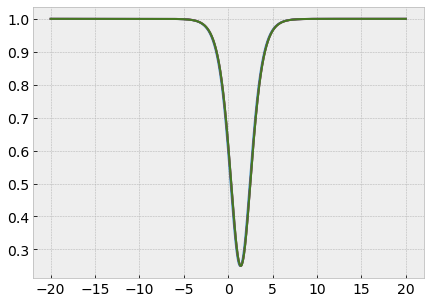

In [107]:
w_1.plot(tf)
w_2.plot(tf)
w_3.plot(tf)
plt.plot(w_1.x, norm(w_soliton(w_1.x-c*tf)))
plt.show()

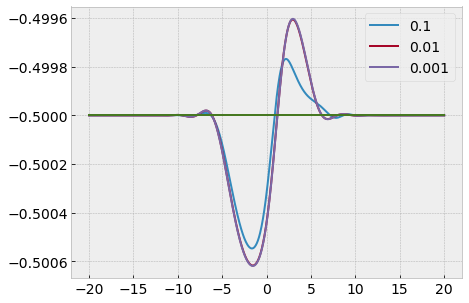

In [108]:
w_1.plot_imag(tf, label="0.1")
w_2.plot_imag(tf, label="0.01")
w_3.plot_imag(tf, label="0.001")
plt.plot(w_1.x, np.imag(w_soliton(w_1.x-c*tf)))

plt.legend()

In [167]:
dt = 0.001
tf = 2

w_1 = CNFD(L, 500, dt, tf, pars, "neumann")
w_2 = CNFD(L, 1000, dt, tf, pars, "neumann")
w_3 = CNFD(L, 2000, dt, tf, pars, "neumann")

w_1.set_init_condition(w_soliton)
w_2.set_init_condition(w_soliton)
w_3.set_init_condition(w_soliton)

w_1.solve()
w_2.solve()
w_3.solve()

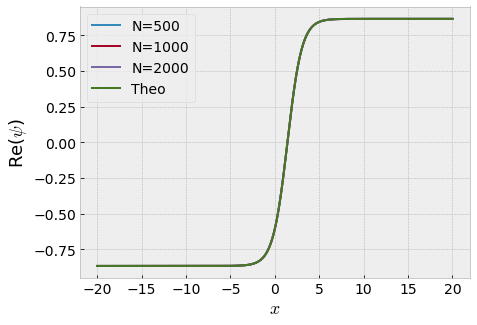

In [168]:
j = 1998
w_1.plot_real(dt * j, label="N=500")
w_2.plot_real(dt * j, label="N=1000")
w_3.plot_real(dt * j, label="N=2000")
plt.plot(w_1.x, np.real(theo(w_1.x-c*dt*j)), label="Theo") #-c*dt*j
plt.xlabel(r"$x$")
plt.ylabel(r"Re($\psi$)")
plt.legend()
plt.savefig("Img/dark_real_GP.png", dpi=300, bbox_inches = "tight")
plt.show()

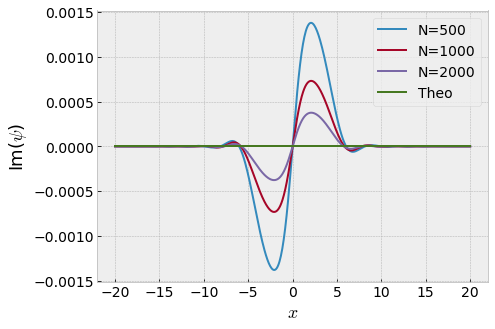

In [165]:
j = 1998
w_1.plot_imag(dt * j, label="N=500")
w_2.plot_imag(dt * j, label="N=1000")
w_3.plot_imag(dt * j, label="N=2000")
plt.plot(w_1.x, np.imag(theo(w_1.x-c*dt*j)), label="Theo") #-c*dt*j
plt.legend()
plt.xlabel(r"$x$")
plt.ylabel(r"Im($\psi$)")
#plt.savefig("Img/black_imag_GP.png", dpi=300, bbox_inches = "tight")
plt.show()

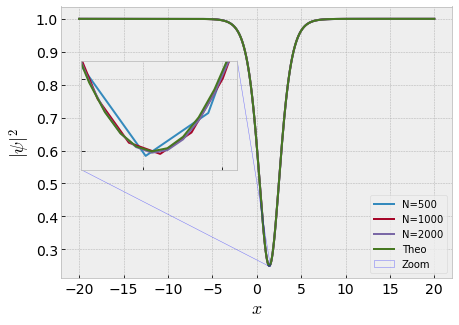

In [159]:
j = 1998
fig = plt.figure()
ax = fig.add_subplot(111)

w_1.plot(dt * j, label="N=500")
w_2.plot(dt * j, label="N=1000")
w_3.plot(dt * j, label="N=2000")
ax.plot(w_1.x, norm(theo(w_1.x-c*dt*j)), label="Theo") #-c*dt*j

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$|\psi|^2$")

ax_mini = ax.inset_axes([0.05, 0.4, 0.4, 0.4])
ax_mini.plot(w_1.x, norm(w_1.w[-1]))
ax_mini.plot(w_2.x, norm(w_2.w[-1]))
ax_mini.plot(w_3.x, norm(w_3.w[-1]))
ax_mini.plot(w_3.x, norm(theo(w_3.x-c*dt*j)))

ax_mini.set_ylim(0.2495, 0.2525)
ax_mini.set_xlim(1.32, 1.52)

ax_mini.set_xticklabels('')
ax_mini.set_yticklabels('')

ax.indicate_inset_zoom(ax_mini, alpha=0.5, edgecolor="blue", label="Zoom")
ax.legend(fontsize=10)
#plt.savefig("Img/dark_GP.png", dpi=300, bbox_inches = "tight")
plt.show()

## Error with theo black soliton

In [109]:
c = 0 #np.sqrt(2)/2
w_soliton, x_soliton = soliton(c, 0, soliton_type="dark", L=L, N=10_000, as_func=True)

def black_theo(x, t):
    return w_soliton(x - c * t)

Creating soliton...
Soliton created


In [113]:
dts = np.array([2**(-j) for j in range(11)])

# Time
tf = 3

# Space
h_1 = 0.05
h_2 = 0.01
L = 20

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1 = np.zeros(len(dts))
error_2 = np.zeros(len(dts))

pars = {"k": 0}

ws_1 = []
ws_2 = []

# N_1
for dt in dts:
    w_ = CNFD(L, N_1, dt, tf, pars, "neumann")
    w_.set_w_theo(black_theo)
    ws_1 += [w_]

# N_2
for dt in dts:
    w_ = CNFD(L, N_2, dt, tf, pars, "neumann")
    w_.set_w_theo(black_theo)
    ws_2 += [w_]

In [114]:
# N_1
for j in range(len(dts)):
    w_ = ws_1[j]
    w_.solve()

In [115]:
# N_2
for j in range(len(dts)):
    w_ = ws_2[j]
    w_.solve()

In [116]:
for j in range(len(dts)):
    e_1 = ws_1[j].get_error(tf)
    e_2 = ws_2[j].get_error(tf)
    
    error_1[j] = e_1
    error_2[j] = e_2

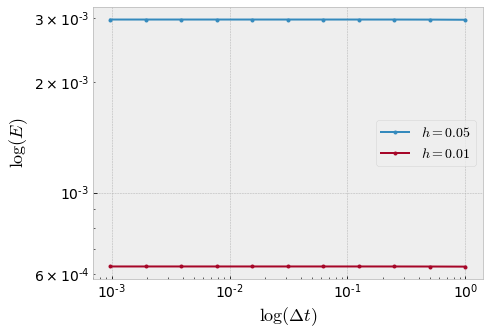

In [117]:
dts_to_plot = dts[:-5]
plt.plot(dts, error_1, ".-", label=r"$h=0.05$")
plt.plot(dts, error_2, ".-", label=r"$h=0.01$")
#plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-2), label="slope-{} line".format(2))
plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

plt.savefig("Img/errors_black.png", dpi=300, bbox_inches = "tight")
plt.show()

## Complex newtown

In [35]:
class Complex_CNFD(Time_CN):
    
    def __init__(self, L, N, dt, tf, pars, border, ti=0):
        super().__init__(L, N, dt, tf, pars, border, ti)
        self.l = self.dt/(self.h**2)


    def F(self, u, v):
        w = u[:self.N]
        w_c = u[self.N:]
        i = 1j
        F_ = i * (v - w) + self.l/2 * self.A * (w + v) + self.dt/2 * (w + v) * (1 - (self.norm(w) + self.norm(v))/2)
        F_conj = F_.conjugate()

        output = np.append(F_, F_conj)
        return output


    def F_prime(self, u, v):

        w = u[:self.N]
        w_c = u[self.N:]

        i = 1j

        norm = self.norm(w)
        norm_n = self.norm(v)


         # Arreglo con las diagonales
        k_dfdw = np.array([self.dt/4 * (2 * norm + v * w_c + norm_n)]) 
        k_dfdw_c = np.array([self.dt/4 *(w**2 + v * w)]) 
        offset = [0] #Posiciones de las diagonales

        dFdw_nl = diags(k_dfdw, offset, format="csc", dtype='complex_')
        dFdw_c_nl = diags(k_dfdw, offset, format="csc", dtype='complex_')

        dFdw = (-i + self.dt/2) * self.I + self.l/2 * self.A - dFdw_nl
        dFdw_c = -dFdw_c_nl
        dF_cdw = dFdw_c.conjugate()
        dF_cdw_c = dFdw.conjugate()

        jac = bmat([[dFdw, dFdw_c], [dF_cdw, dF_cdw_c]], format="csc", dtype="complex_")
        return jac


    def update(self, n):
        i=1j
        # Actual state
        wn = self.w[n]
        wn_c = wn.conjugate()
        wn_to_solve = np.append(wn, wn_c)

        def F_(X):
            output = self.F(X, wn)
            return output

        def F_prime_(X):
            output = self.F_prime(X, wn)
            return output

        w_n_1, error = self.newton(wn_to_solve, F_, F_prime_)

        self.w[n+1] = w_n_1[:self.N]


In [104]:
tf = 5
L = 20

c = 0#np.sqrt(2)/2
k = 0 #0.0625

pars = {"k":k}

# Theretical solitons_
w_soliton, x_soliton = soliton(c, k, soliton_type="dark", L=L, N=10_000, as_func=True)

Creating soliton...
Soliton created


In [116]:
dt =  0.01
N = 1000

w_real = Real_CNFD(L, N, dt, tf, pars, "neumann")
w_real.set_init_condition(w_soliton)
w_real.solve()

w_comp = Complex_CNFD(L, N, dt, tf, pars, "neumann")
w_comp.set_init_condition(w_soliton)
w_comp.solve()


t_ex_r = w_real.get_execution_time()
print("Execution time reals:", round(t_ex_r, 3))

t_ex_c = w_comp.get_execution_time()
print("Execution time complex:", round(t_ex_c, 3))

Execution time reals: 2.026
Execution time complex: 3.208


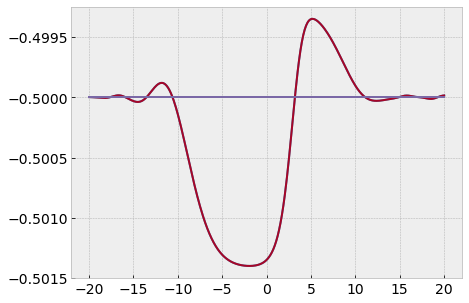

In [101]:
w_real.plot_imag(tf)
w_comp.plot_imag(tf)
plt.plot(w_real.x, np.imag(w_soliton(w_real.x-c*tf)))
plt.show()

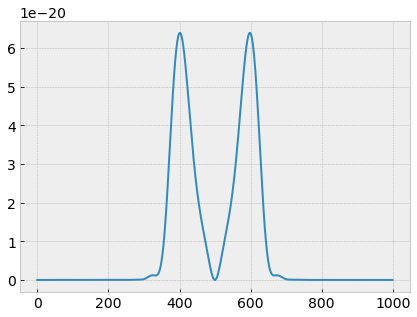

In [53]:
h = 2*L/N

n = int(tf//dt)
w_r = w_real.w[n]
w_c = w_comp.w[n]

diff = np.abs(w_r - w_c)**2
sum_ = np.sum(diff)
output = np.sqrt(h * sum_)

plt.plot(diff)

In [8]:
c = 0 #np.sqrt(2)/2

def dark_soliton(x):
    i = 1j
    A = np.sqrt((2-c**2)/2)
    sum_1 = A * np.tanh(np.sqrt(2-c**2)/2 * x)
    sum_2 = i*c/np.sqrt(2)

    return sum_1 - sum_2

def solve_complex(N, dt, tf, L):
    Nt = int(tf//dt)
    dx = 2*L/N

    l = dt/dx**2

    w = np.zeros((Nt, N), dtype='complex_')

    e = np.ones(N, dtype = 'float64') * -2

    e[0] = -1
    e[-1] = -1

    f = np.ones(N-1, dtype = 'float64')

     # Arreglo con las diagonales
    k_ = np.array([f,e,f], dtype=object) 
    offset = [-1,0,1] #Posiciones de las diagonales

    A = diags(k_, offset, format="csc", dtype='float64')


    def newton(x_0, f, f_prime, args, args_der, tol=1e-8):
        x_k = x_0
        error = np.add.reduce(np.abs(f(x_k, args)))
        while error > tol:
            f_1 = -f(x_k, args)
            f_2 = f_prime(x_k, args_der)
            delta_x = spsolve(f_2, f_1)
            x_k = x_k + delta_x
            error = np.add.reduce(np.abs(f(x_k, args)))

        return x_k, error


    def F(Z, wn):
        w = Z[:N]
        w_c = Z[N:]
        i = 1j
        F_ = i * (wn - w) + l/2 * A*(w + wn) + dt/2 * (w + wn) * (1 - (np.abs(w)**2 + np.abs(wn)**2)/2)
        F_conj = F_.conjugate()

        output = np.append(F_, F_conj)
        return output


    def F_prime(Z, wn):

        w = Z[:N]
        w_c = Z[N:]

        i = 1j
        I = identity(len(w), format="csc")

        norm = np.abs(w)**2
        norm_n = np.abs(wn)**2


         # Arreglo con las diagonales
        k_dfdw = np.array([dt/4 * (2 * norm + wn * w_c + norm_n)]) 
        k_dfdw_c = np.array([dt/4 *(w**2 + wn * w)]) 
        offset = [0] #Posiciones de las diagonales

        dFdw_nl = diags(k_dfdw, offset, format="csc", dtype='complex_')
        dFdw_c_nl = diags(k_dfdw, offset, format="csc", dtype='complex_')

        dFdw = (-i + dt/2) * I + l/2 * A - dFdw_nl
        dFdw_c = -dFdw_c_nl
        dF_cdw = dFdw_c.conjugate()
        dF_cdw_c = dFdw.conjugate()

        jac = bmat([[dFdw, dFdw_c], [dF_cdw, dF_cdw_c]], format="csc", dtype="complex_")
        return jac


    w[0] = dark_soliton(x)

    ti_test = time()

    for n in range(Nt-1):
        wn = w[n]
        wn_c = np.conjugate(wn)

        wn_to_solve = np.append(wn, wn_c)
        w_n_1, error = newton(wn_to_solve, F, F_prime, args=wn, args_der=wn) # # error
        w[n+1] = w_n_1[:N]

    tf_test = time()

    print("Execution time complex:", round((tf_test-ti_test), 3))
    
    return w

In [11]:
N = 500
dt = 0.1
tf = 2
L = 20
pars = {"k": 0}

x = np.linspace(-L, L, N)

w_comp = solve_complex(N, dt, tf, L)

w_real = CNFD(L, N, dt, tf, pars, "neumann")
w_real.set_init_condition(dark_soliton)
w_real.solve()

t_ex = w_real.get_execution_time()
print("Execution time reals:", round(t_ex, 3))

Execution time complex: 0.198
Execution time reals: 0.116


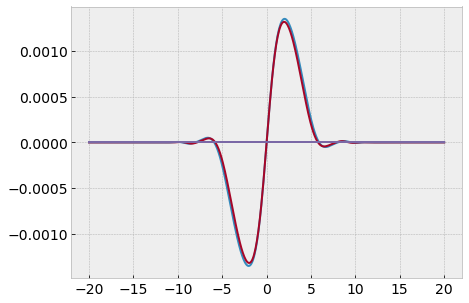

In [12]:
i = 1j
j = int(tf//dt)-1 #198

#for j in range(0, 1998, 20):
t = tf #dt * j
w_real.plot_imag(t)
plt.plot(x, np.imag(w_comp[j]))
plt.plot(x, np.imag(dark_soliton(x-c*t)))
plt.show()

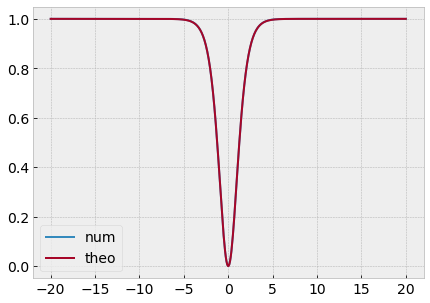

In [194]:
plt.plot(x, norm(w[j]), label="num")
plt.plot(x, norm(dark_soliton(x-c*t)), label="theo")
plt.legend()
plt.show()